# A03 · Limpieza y análisis exploratorio: Room Occupancy Estimation

**Objetivo:** evaluar y recuperar la calidad de `modified.csv` respecto a `original.csv` sin utilizar el archivo original durante el tratamiento. Dataset de sensores de temperatura, luz, sonido, CO₂, movimiento PIR y número de ocupantes.

**Reproducibilidad:** los archivos CSV se buscan en `room-occupancy-estimation/` junto al notebook (o en `room-occupancy-estimation/` cuando el notebook está en el directorio superior). Las métricas utilizan el original **exclusivamente como referencia de evaluación**. Los indicadores se calculan en ejecución.



## 1. Preparación y contrato de datos

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid')
base = Path('room-occupancy-estimation')
if not base.exists():
    base = Path('a03_work/room-occupancy-estimation')
assert base.exists(), 'Coloca la carpeta room-occupancy-estimation junto al notebook.'
original = pd.read_csv(base/'original.csv')
raw = pd.read_csv(base/'modified.csv', dtype='string')
contract = original.columns.tolist() # contrato de columnas, NO valores usados para reparar
TARGET = 'Room_Occupancy_Count'
FEATURES = [x for x in contract if x not in ['Date','Time',TARGET]]
print('Original:', original.shape, '| Perturbado:',raw.shape)
print('Columnas adicionales:',set(raw)-set(contract))
display(raw.head())

Original: (10129, 19) | Perturbado: (10331, 20)
Columnas adicionales: {'mixed_type_col'}


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,<NA>
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown
3,2017/12/22,10:51:13,25.0,24.75,24.56,25.44,121.0,34.0,53.0,40.0,0.41,0.1,0.1,0.09,390.0,0.388461538462,0.0,0.0,1.0,584
4,2017/12/22,10:51:44,25.0,24.75,24.56,25.44,121.0,34.0,54.0,40.0,0.18,0.06,0.06,0.06,390.0,0.253846153846,0.0,0.0,1.0,bad


## 2. Diagnóstico (antes de modificar)

Se revisan esquema, faltantes reales y aparentes, duplicados, valores no numéricos, dominio de etiquetas y fechas. Las cadenas `?`, `bad`, `unknown`, etc. son tratadas como datos inválidos, no como medidas.

In [3]:
bad_tokens = {'', '?','na','n/a','nan','none','null','unknown','bad','missing','error','-'}
normalized = raw.apply(lambda s:s.str.strip())
placeholders = normalized.apply(lambda s:s.str.lower().isin(bad_tokens).sum())
invalid_num = {}
for col in FEATURES+[TARGET]:
    x=normalized[col].mask(normalized[col].str.lower().isin(bad_tokens))
    invalid_num[col]=int((x.notna() & pd.to_numeric(x,errors='coerce').isna()).sum())
quality = pd.DataFrame({'faltantes':raw.isna().sum(),'tokens_invalidos':placeholders,'numeros_no_convertibles':pd.Series(invalid_num)})
display(quality.fillna(0).astype(int))
print('Duplicados exactos crudos:',raw.duplicated().sum())
print('Etiquetas numéricas observadas:',sorted(pd.to_numeric(normalized[TARGET],errors='coerce').dropna().unique().tolist())[:30])

,faltantes,tokens_invalidos,numeros_no_convertibles
Date,90,3,0
Room_Occupancy_Count,132,28,12
S1_Light,114,28,6
S1_Sound,110,28,8
S1_Temp,115,34,8
S2_Light,122,24,16
S2_Sound,115,27,14
S2_Temp,128,27,8
S3_Light,131,31,14
S3_Sound,103,22,13


Duplicados exactos crudos: 1
Etiquetas numéricas observadas: [0.0, 1.0, 2.0, 3.0, 40.0, 102.0, 120.0, 130.0, 135.0, 143.0, 147.0, 177.0, 194.0, 219.0, 261.0, 264.0, 297.0, 307.0, 309.0, 349.0, 364.0, 379.0, 386.0, 421.0, 432.0, 464.0, 484.0, 518.0, 547.0, 550.0]


## 3. Normalización, validación y deduplicación

In [4]:
def parse_data(raw_df):
    d=raw_df.copy()
    for col in d.columns:
        d[col]=d[col].str.strip().mask(d[col].str.strip().str.lower().isin(bad_tokens))
    d=d.reindex(columns=contract)  # elimina columna espuria
    for col in FEATURES+[TARGET]:
        d[col]=pd.to_numeric(d[col],errors='coerce')
    d['timestamp']=pd.to_datetime(d['Date'].fillna('')+' '+d['Time'].fillna(''),format='%Y/%m/%d %H:%M:%S',errors='coerce')
    d[TARGET]=d[TARGET].where(d[TARGET].isin([0,1,2,3]))
    for col in ['S6_PIR','S7_PIR']:
        d[col]=d[col].where(d[col].isin([0,1]))
    for col in FEATURES:
        if col.startswith(('S1_Light','S2_Light','S3_Light','S4_Light','S1_Sound','S2_Sound','S3_Sound','S4_Sound')) or col=='S5_CO2':
            d[col]=d[col].where(d[col]>=0)
    return d
parsed=parse_data(raw)
print('Fechas nulas:',parsed.timestamp.isna().sum())
print('Timestamps repetidos (sin incluir NaT):',parsed.timestamp.dropna().duplicated().sum())
print('Faltantes tras conversión:',int(parsed[FEATURES+[TARGET]].isna().sum().sum()))
# Un timestamp duplicado puede contener mediciones dañadas en una de las copias.
# Se conservan las celdas disponibles mediante mediana por variable y moda en la etiqueta.
def mode_safe(x):
    v=x.dropna().mode(); return v.iloc[0] if len(v) else np.nan
valid=parsed.dropna(subset=['timestamp']).copy()
agg={col:'median' for col in FEATURES}; agg[TARGET]=mode_safe
unique=valid.groupby('timestamp',as_index=False).agg(agg).sort_values('timestamp').reset_index(drop=True)
print('Registros únicos con fecha válida:',len(unique))

Fechas nulas: 197
Timestamps repetidos (sin incluir NaT): 189
Faltantes tras conversión: 2755
Registros únicos con fecha válida: 9945


## 4. Detección de anomalías

Se aplican **límites físicos conservadores** (temperaturas 0–50 °C, luz 0–2000, sonido 0–10, CO₂ 250–10,000 ppm y pendiente absoluta hasta 1000) y, después, **saltos locales** respecto de una mediana móvil de 11 muestras, pero solo cuando el salto es extremo en comparación con el rango intercuartílico global. Se evita usar exclusivamente IQR porque cambios reales de ocupación pueden generar valores altos legítimos. No se corrige la etiqueta mediante interpolación.

In [5]:
def flag_outliers(df):
    d=df.copy(); flagged={}
    for col in FEATURES:
        x=d[col].astype(float)
        if 'Temp' in col: lo,hi=0,50
        elif 'Light' in col: lo,hi=0,2000
        elif 'Sound' in col: lo,hi=0,10
        elif col=='S5_CO2': lo,hi=250,10000
        elif col=='S5_CO2_Slope': lo,hi=-1000,1000
        else: continue
        physical=x.notna() & ~x.between(lo,hi)
        q1,q3=x.quantile([.25,.75]); iqr=q3-q1
        rolling=x.rolling(11,center=True,min_periods=5).median()
        # salto muy grande respecto al rango de la serie Y ruido local de mediciones
        local=(x-rolling).abs()>max(12*iqr, 1e-6)
        if 'Temp' in col: local &= (x-rolling).abs()>5
        if 'CO2' in col: local &= (x-rolling).abs()>600
        flag=physical|local
        d.loc[flag,col]=np.nan
        flagged[col]=int(flag.sum())
    return d,pd.Series(flagged,name='outliers_marcados')
filtered,flagged=flag_outliers(unique)
display(flagged.to_frame());print('Total marcado:',flagged.sum())

,outliers_marcados
S1_Temp,109
S2_Temp,107
S3_Temp,106
S4_Temp,92
S1_Light,68
S2_Light,70
S3_Light,24
S4_Light,69
S1_Sound,1107
S2_Sound,873


Total marcado: 3700


## 5. Comparar tratamientos para datos faltantes

Se presentan tres opciones: **A** eliminar filas incompletas, **B** imputación por mediana global y **C** interpolación temporal limitada (máximo 4 puntos internos) más mediana como respaldo. Para el objetivo, se elimina cualquier fila sin etiqueta válida: inventarla produciría falsas respuestas supervisadas. La temporalidad se respeta para sensores continuos, no para etiquetas ni PIR (estos se imputan con moda).

In [6]:
sensor_cols=[x for x in FEATURES if x not in ['S6_PIR','S7_PIR']]
pir=['S6_PIR','S7_PIR']
base_labeled=filtered.dropna(subset=[TARGET]).copy()
strategy_a=base_labeled.dropna(subset=FEATURES).copy()
strategy_b=base_labeled.copy()
strategy_c=base_labeled.copy()
for col in sensor_cols:
    strategy_b[col]=strategy_b[col].fillna(strategy_b[col].median())
    strategy_c[col]=strategy_c[col].interpolate(method='linear',limit=4,limit_area='inside').fillna(strategy_c[col].median())
for col in pir:
    typical=mode_safe(base_labeled[col])
    strategy_b[col]=strategy_b[col].fillna(typical)
    strategy_c[col]=strategy_c[col].ffill(limit=2).bfill(limit=2).fillna(typical)
for d in [strategy_b,strategy_c]:
    for col in pir+[TARGET]:d[col]=d[col].astype('int64')
summary=pd.DataFrame({'filas':[len(strategy_a),len(strategy_b),len(strategy_c)],'faltantes_predictoras':[strategy_a[FEATURES].isna().sum().sum(),strategy_b[FEATURES].isna().sum().sum(),strategy_c[FEATURES].isna().sum().sum()]},index=['A. Filas completas','B. Mediana/moda','C. Temporal/mediana'])
display(summary)
cleaned=strategy_c.copy()
cleaned['Date']=cleaned.timestamp.dt.strftime('%Y/%m/%d')
cleaned['Time']=cleaned.timestamp.dt.strftime('%H:%M:%S')
cleaned=cleaned[contract]
cleaned.to_csv('A03_room_occupancy_cleaned.csv',index=False)
print('Guardado A03_room_occupancy_cleaned.csv')

,filas,faltantes_predictoras
A. Filas completas,5858,0
B. Mediana/moda,9742,0
C. Temporal/mediana,9742,0


Guardado A03_room_occupancy_cleaned.csv


## 6. EDA: distribución de ocupación, sensores y relaciones

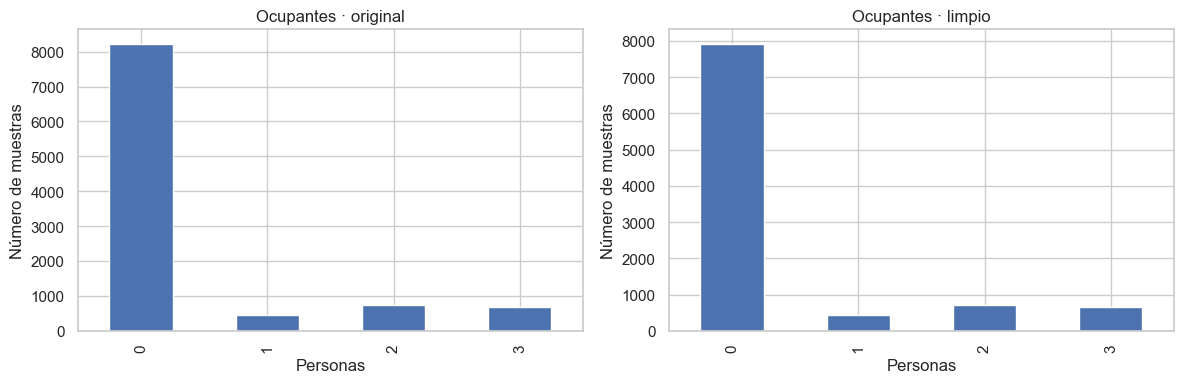

,original,limpio
Room_Occupancy_Count,,
0,81.23,81.29
1,4.53,4.49
2,7.38,7.40
3,6.85,6.83


In [7]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
original[TARGET].value_counts().sort_index().plot.bar(ax=ax[0],title='Ocupantes · original')
cleaned[TARGET].value_counts().sort_index().plot.bar(ax=ax[1],title='Ocupantes · limpio')
for a in ax:a.set_xlabel('Personas');a.set_ylabel('Número de muestras')
plt.tight_layout();plt.show()
comparison_class=pd.concat([original[TARGET].value_counts(normalize=True).sort_index().rename('original'),cleaned[TARGET].value_counts(normalize=True).sort_index().rename('limpio')],axis=1)*100
display(comparison_class.round(2))

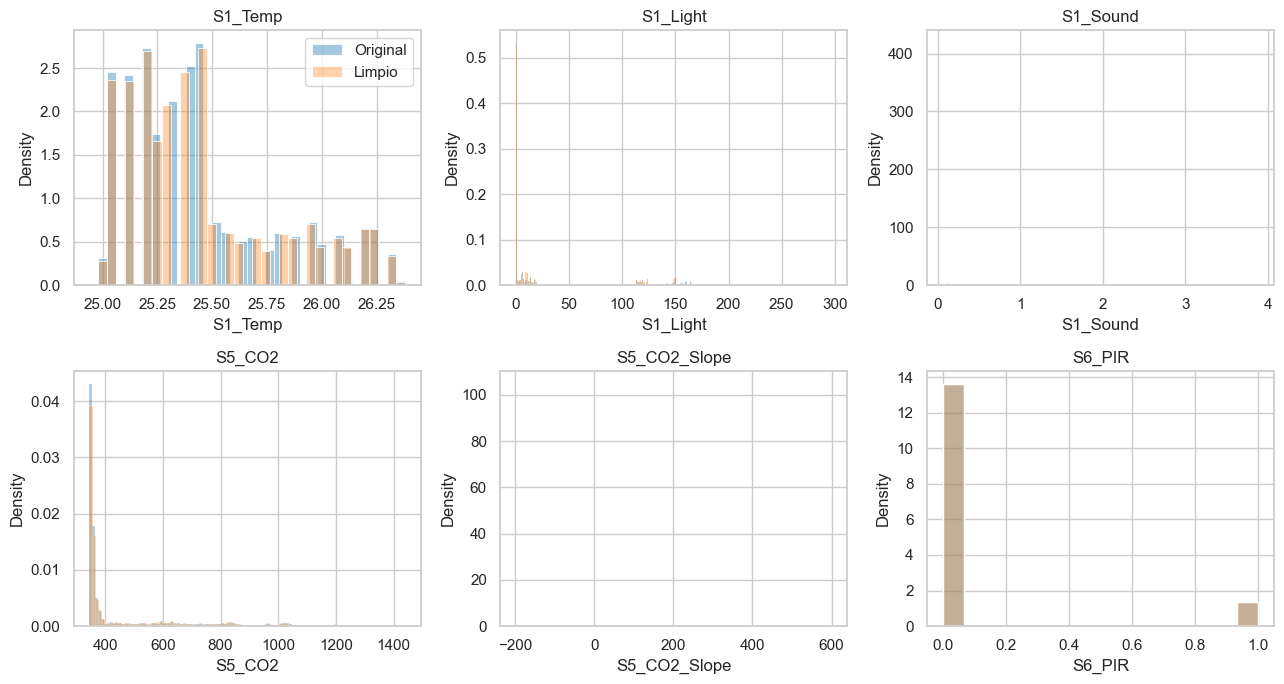

In [8]:
fig,ax=plt.subplots(2,3,figsize=(13,7))
for a,col in zip(ax.flat,['S1_Temp','S1_Light','S1_Sound','S5_CO2','S5_CO2_Slope','S6_PIR']):
    sns.histplot(original[col],ax=a,stat='density',label='Original',color='tab:blue',alpha=.4)
    sns.histplot(cleaned[col],ax=a,stat='density',label='Limpio',color='tab:orange',alpha=.35)
    a.set_title(col)
ax[0,0].legend();plt.tight_layout();plt.show()

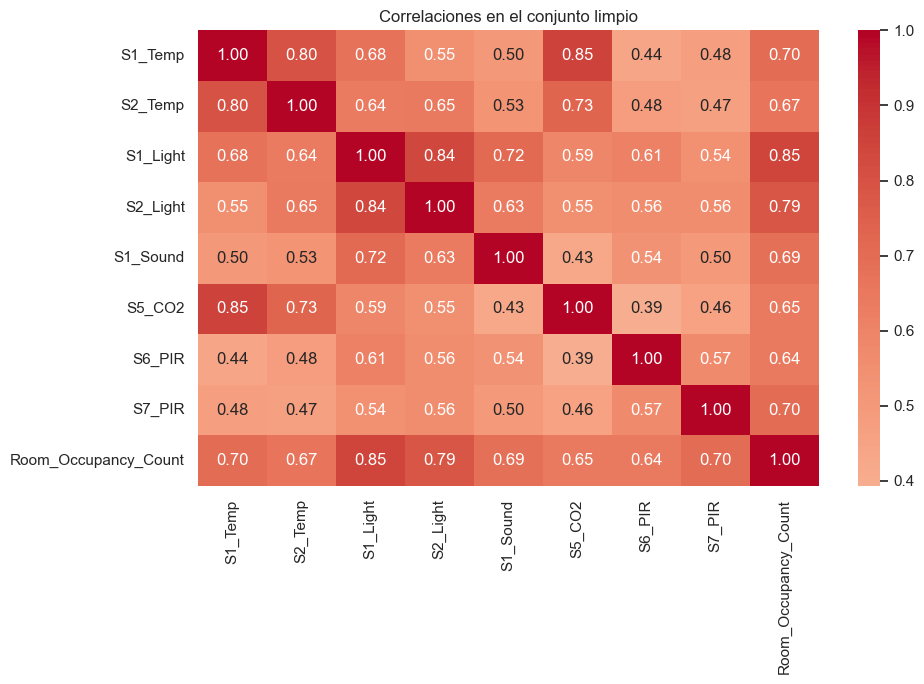

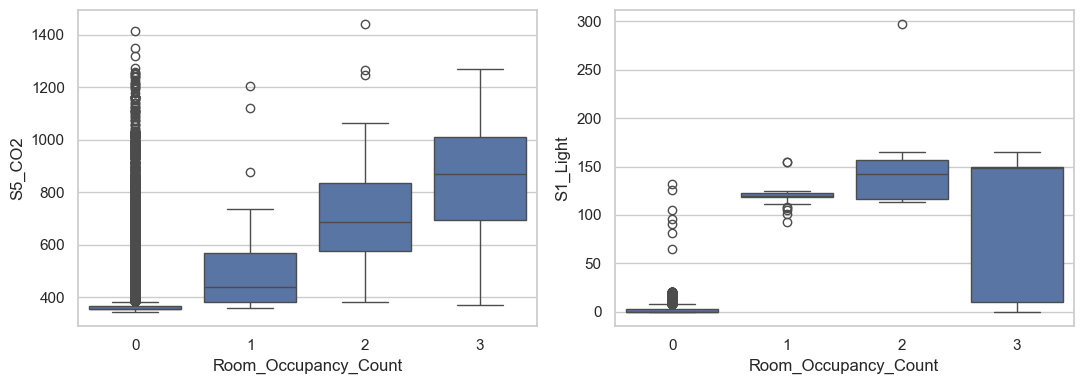

In [9]:
selected=['S1_Temp','S2_Temp','S1_Light','S2_Light','S1_Sound','S5_CO2','S6_PIR','S7_PIR',TARGET]
fig,ax=plt.subplots(figsize=(10,7))
sns.heatmap(cleaned[selected].corr(),cmap='coolwarm',center=0,annot=True,fmt='.2f',ax=ax)
ax.set_title('Correlaciones en el conjunto limpio');plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=cleaned,x=TARGET,y='S5_CO2',ax=axs[0])
sns.boxplot(data=cleaned,x=TARGET,y='S1_Light',ax=axs[1])
plt.tight_layout();plt.show()

## 7. Comparación final contra el conjunto original

Se enlazan las filas por `timestamp`, no por posición: los duplicados insertados y las fechas vacías impiden una correspondencia por índice. **Cobertura** = porcentaje de tiempos originales recuperados; **MAE** = error absoluto promedio en celdas emparejadas; se compara contra la versión perturbada convertida numéricamente sin imputar (solo en sus valores disponibles). El MAE observado puede favorecer injustamente a un método que descarta las celdas más dañadas; por eso se muestra también cobertura de celdas.

In [10]:
ref=original.copy()
ref['timestamp']=pd.to_datetime(ref['Date']+' '+ref['Time'],format='%Y/%m/%d %H:%M:%S')
ref=ref.set_index('timestamp')
raw_baseline=unique.set_index('timestamp')
methods={'Perturbado (parseado)':raw_baseline,'A. Filas completas':strategy_a.set_index('timestamp'),'B. Mediana/moda':strategy_b.set_index('timestamp'),'C. Temporal/mediana':strategy_c.set_index('timestamp')}
rows=[]
for name,d in methods.items():
    idx=ref.index.intersection(d.index)
    rr=ref.loc[idx,FEATURES]; dd=d.loc[idx,FEATURES]
    count=dd.notna().sum().sum()
    mae=(rr-dd).abs().stack().mean() if count else np.nan
    occ=ref.loc[idx,TARGET].eq(d.loc[idx,TARGET]).mean()
    rows.append({'estrategia':name,'filas':len(d),'cobertura_tiempos_%':100*len(idx)/len(ref),'cobertura_celdas_%':100*count/(len(ref)*len(FEATURES)),'MAE_sensores_unidades_mixtas':mae,'acierto_etiqueta_%':100*occ})
metrics=pd.DataFrame(rows).set_index('estrategia')
display(metrics.round(3))
# Error por característica, sin combinar unidades físicamente distintas
per_feature=pd.DataFrame(index=FEATURES)
for name,d in methods.items():
    idx=ref.index.intersection(d.index)
    per_feature[name]=(ref.loc[idx,FEATURES]-d.loc[idx,FEATURES]).abs().mean()
display(per_feature.round(3))
print('Filas originales no recuperadas en estrategia C:',len(ref.index.difference(strategy_c.timestamp)))
print('Distribución original de clases:',original[TARGET].value_counts().sort_index().to_dict())
print('Distribución limpia de clases:',cleaned[TARGET].value_counts().sort_index().to_dict())

,filas,cobertura_tiempos_%,cobertura_celdas_%,MAE_sensores_unidades_mixtas,acierto_etiqueta_%
estrategia,,,,,
Perturbado (parseado),9945,98.183,96.701,14.175,100.0
A. Filas completas,5858,57.834,57.834,0.304,100.0
B. Mediana/moda,9742,96.179,96.179,0.589,100.0
C. Temporal/mediana,9742,96.179,96.179,0.311,100.0


,Perturbado (parseado),A. Filas completas,B. Mediana/moda,C. Temporal/mediana
S1_Temp,10.565,0.0,0.007,0.0
S2_Temp,10.288,0.0,0.008,0.0
S3_Temp,10.448,0.0,0.009,0.0
S4_Temp,8.524,0.0,0.006,0.001
S1_Light,10.372,0.06,0.584,0.078
S2_Light,7.473,0.036,0.534,0.058
S3_Light,9.947,1.171,1.701,0.994
S4_Light,7.114,0.155,0.525,0.177
S1_Sound,2.805,0.0,0.07,0.055
S2_Sound,2.505,0.0,0.049,0.038


Filas originales no recuperadas en estrategia C: 387
Distribución original de clases: {0: 8228, 1: 459, 2: 748, 3: 694}
Distribución limpia de clases: {0: 7919, 1: 437, 2: 721, 3: 665}


## 8. Conclusiones y recomendaciones

- Los datos se validan por contrato y se descarta la columna espuria. La reparación no utiliza mediciones del original.
- Los duplicados por momento se consolidan; filas sin fecha interpretable o sin etiqueta se excluyen, para no fabricar observaciones/objetivos.
- La imputación temporal mantiene continuidad de sensores; los PIR se tratan como indicadores discretos. La eliminación total ofrece mayor pureza pero puede reducir mucho la cobertura.
- El análisis por timestamp mide fidelidad y retención simultáneamente. El error conjunto en unidades mixtas es orientativo: priorizar errores por variable y conservar un juego de validación no perturbado.
- **Precaución para ML:** separar entrenamiento/prueba por fechas (no aleatoriamente), ajustar imputadores solo con entrenamiento y monitorizar deriva, porque observaciones cercanas temporalmente están correlacionadas.